# Test final del experimento BCS - Modelo YOLO + Regresion

In [67]:
# Instalamos únicamente Ultralytics si falta; mantenemos los frameworks de Kaggle.
import importlib.util
import importlib.metadata
import subprocess
import sys

ULTRALYTICS_VERSION = "8.4.0"
if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        f"ultralytics=={ULTRALYTICS_VERSION}"
    ])
else:
    version = importlib.metadata.version("ultralytics")
    if version != ULTRALYTICS_VERSION:
        raise RuntimeError(
            f"Ultralytics instalado: {version}. Este experimento utiliza "
            f"{ULTRALYTICS_VERSION}; prepara esa versión antes de continuar."
        )

## 1. Localizar los outputs del entrenamiento

Deja `ORIGEN_ENTRENAMIENTO = None` para buscar una única carpeta de v2 adjunta. Si hay varias versiones, escribe la ruta de la que corresponde al notebook entrenado v2. También puedes proporcionar directamente la ruta del ZIP.

Se copian únicamente los modelos elegidos, su configuración y la selección. No se descargan pesos iniciales ni se vuelven a entrenar redes. Si faltan outputs, la celda se detiene.

In [68]:
from pathlib import Path
from collections import defaultdict, Counter
import gc
import hashlib
import json
import math
import re
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps
from IPython.display import display
import torch
from ultralytics import YOLO

ORIGEN_ENTRENAMIENTO = "/kaggle/working/bcs_secuencial_v2_regresion"  # "/kaggle/input/<outputs>/bcs_secuencial_v2_regresion"
DATOS = None  # Carpeta que contiene train, valid y test; None la busca automáticamente.
SALIDA = Path("/kaggle/working/bcs_secuencial_v2_regresion_test")
PARTICION_EVALUACION = "test"
TEST_FINAL_CONFIRMADO = True
TOLERANCIA_CAJA = 0.02
SALIDA.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), "Activa GPU en Kaggle."

In [69]:
# Esta función solo calcula la huella de un archivo, sin cargarlo entero en memoria.
def huella_archivo(ruta):
    huella = hashlib.sha256()
    with Path(ruta).open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    return huella.hexdigest()

In [70]:
if ORIGEN_ENTRENAMIENTO is None:
    candidatas = []
    for ruta in Path("/kaggle/input").rglob("configuracion.json"):
        configuracion_candidata = json.loads(ruta.read_text())
        if (configuracion_candidata.get("version") == "secuencial_2_regresion"
                and (ruta.parent / "seleccion_regresor.json").is_file()
                and (ruta.parent / "detector/weights/best.pt").is_file()):
            candidatas.append(ruta.parent)
    if not candidatas:
        candidatas = sorted(Path("/kaggle/input").rglob("bcs_secuencial_v2_regresion_resultados.zip"))
    assert len(candidatas) == 1, f"Indica ORIGEN_ENTRENAMIENTO. Candidatas: {candidatas}"
    ORIGEN_ENTRENAMIENTO = candidatas[0]

origen = Path(ORIGEN_ENTRENAMIENTO)
if origen.suffix.lower() == ".zip":
    carpeta_extraida = Path("/kaggle/working/outputs_v2_recuperados")
    carpeta_extraida.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(origen) as archivo:
        for entrada in archivo.infolist():
            destino = (carpeta_extraida / entrada.filename).resolve()
            assert destino.is_relative_to(carpeta_extraida.resolve()), "Ruta ZIP inválida."
        archivo.extractall(carpeta_extraida)
    candidatas = sorted(carpeta_extraida.rglob("seleccion_regresor.json"))
    assert len(candidatas) == 1, "El ZIP debe contener una sola selección de regresor."
    origen = candidatas[0].parent

configuracion = json.loads((origen / "configuracion.json").read_text())
seleccion_regresor = json.loads((origen / "seleccion_regresor.json").read_text())
assert configuracion["version"] == "secuencial_2_regresion", "Se necesitan los outputs de v2."
fase = seleccion_regresor["fase"]
assert fase in ("cabeza", "ajuste_fino")
assert fase == min(seleccion_regresor["mae_validacion"], key=seleccion_regresor["mae_validacion"].get)
checkpoint_relativo = Path("regresor") / fase / "best.keras"
assert Path(seleccion_regresor["checkpoint"]) == checkpoint_relativo

for relativa in [Path("configuracion.json"), Path("seleccion_regresor.json"),
                 Path("detector/weights/best.pt"), checkpoint_relativo]:
    fuente, destino = origen / relativa, SALIDA / relativa
    assert fuente.is_file(), f"Falta output entrenado: {fuente}"
    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        assert huella_archivo(destino) == huella_archivo(fuente), "Salida existente de otro modelo."
    else:
        shutil.copy2(fuente, destino)

ruta_configuracion = SALIDA / "configuracion.json"
MEJOR_YOLO = SALIDA / "detector/weights/best.pt"
MEJOR_REGRESOR = SALIDA / checkpoint_relativo
SEMILLA = configuracion["semilla"]
TAM_YOLO = configuracion["yolo"]["tam"]
LOTE_YOLO = configuracion["yolo"]["lote"]
TAM_RECORTE = configuracion["regresor"]["tam"]
CONFIANZA = configuracion["inferencia"]["confianza"]
COBERTURA_GRUPA = configuracion["inferencia"]["cobertura"]
assert configuracion["yolo"]["version"] == ULTRALYTICS_VERSION
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print("Fase fijada en validación:", fase)
print("MAE de validación:", seleccion_regresor["mae_validacion"][fase])
print("Confianza:", CONFIANZA, "| Cobertura mínima de grupa:", COBERTURA_GRUPA)

Fase fijada en validación: cabeza
MAE de validación: 0.2346049100160598
Confianza: 0.25 | Cobertura mínima de grupa: 0.8


## 2. Comprobar el dataset original

Repetimos la auditoría de imágenes, cajas, identidades y duplicados del entrenamiento. Después comprobamos que sus huellas, etiquetas y particiones coinciden con la configuración guardada. No creamos nuevas particiones ni recalculamos la selección con test.

In [71]:
if DATOS is None:
    candidatas = sorted({
        p.parent.parent
        for p in Path("/kaggle/input").rglob("_annotations.coco.json")
        if p.parent.name == "train"
        and (p.parent.parent / "valid/_annotations.coco.json").is_file()
        and (p.parent.parent / "test/_annotations.coco.json").is_file()
    })
    if len(candidatas) != 1:
        raise RuntimeError(f"Especifica DATOS manualmente. Candidatas: {candidatas}")
    DATOS = candidatas[0]
DATOS = Path(DATOS)

coco = {}
for carpeta, particion in [("train", "train"), ("valid", "val"), ("test", "test")]:
    coco[particion] = json.loads((DATOS / carpeta / "_annotations.coco.json").read_text())
    contenido = coco[particion]
    print(particion, "| imágenes:", len(contenido["images"]),
          "| cajas:", len(contenido["annotations"]),
          "| categorías:", [(c["id"], c["name"]) for c in contenido["categories"]])

train | imágenes: 243 | cajas: 486 | categorías: [(0, 'Vacones-BCS-Cajas-v2-Aprobado'), (1, 'ass'), (2, 'cow')]
val | imágenes: 36 | cajas: 72 | categorías: [(0, 'Vacones-BCS-Cajas-v2-Aprobado'), (1, 'ass'), (2, 'cow')]
test | imágenes: 56 | cajas: 112 | categorías: [(0, 'Vacones-BCS-Cajas-v2-Aprobado'), (1, 'ass'), (2, 'cow')]


In [72]:
filas = []
correcciones = []
for carpeta, particion in [("train", "train"), ("valid", "val"), ("test", "test")]:
    contenido = coco[particion]
    categorias = {c["id"]: c["name"] for c in contenido["categories"]}
    imagenes = {im["id"]: im for im in contenido["images"]}
    assert len(categorias) == len(contenido["categories"]), "Categorías duplicadas."
    assert {"cow", "ass"} <= set(categorias.values()), "Faltan clases cow/ass."
    assert len(imagenes) == len(contenido["images"]), "IDs de imagen duplicados."
    assert len({a["id"] for a in contenido["annotations"]}) == len(contenido["annotations"])
    anotaciones = defaultdict(list)
    for anotacion in contenido["annotations"]:
        assert anotacion["image_id"] in imagenes, "Referencia de imagen inválida."
        assert categorias[anotacion["category_id"]] in ("cow", "ass")
        assert anotacion.get("iscrowd", 0) == 0, "Revisar anotación iscrowd."
        anotaciones[anotacion["image_id"]].append(anotacion)

    nombres = set()
    for imagen in contenido["images"]:
        nombre = imagen["file_name"]
        assert Path(nombre).name == nombre and "\\" not in nombre
        assert nombre not in nombres, "Nombre de imagen duplicado."
        nombres.add(nombre)
        ruta = DATOS / carpeta / nombre
        with Image.open(ruta) as foto:
            assert foto.size == (imagen["width"], imagen["height"]), str(ruta)
            foto.verify()
        with Image.open(ruta) as foto:
            foto.convert("RGB").load()

        etiquetas = imagen.get("extra", {}).get("user_tags", [])
        identidades = sorted({str(t) for t in etiquetas if re.fullmatch(r"\d+", str(t))})
        etiquetas_bcs = sorted({str(t) for t in etiquetas if str(t).startswith("BCS_")})
        assert identidades, f"Falta identidad para comprobar la partición: {nombre}"
        bcs = None
        if len(identidades) == len(etiquetas_bcs) == 1:
            coincidencia = re.fullmatch(r"BCS_(\d+)(?:_(\d+))?", etiquetas_bcs[0])
            if coincidencia:
                bcs = float(coincidencia[1] + ("." + coincidencia[2] if coincidencia[2] else ""))
                assert 1 <= bcs <= 5, f"BCS fuera de rango: {nombre}"

        cajas = []
        for anotacion in anotaciones[imagen["id"]]:
            x, y, ancho, alto = anotacion["bbox"]
            assert all(math.isfinite(v) for v in (x, y, ancho, alto))
            assert ancho > 0 and alto > 0
            exceso = max(0, -x, -y, x + ancho - imagen["width"], y + alto - imagen["height"])
            assert exceso <= TOLERANCIA_CAJA + 1e-9, f"Caja fuera de imagen: {nombre}"
            xyxy = [max(0, x), max(0, y), min(imagen["width"], x + ancho),
                    min(imagen["height"], y + alto)]
            assert xyxy[2] > xyxy[0] and xyxy[3] > xyxy[1]
            if exceso > 1e-9:
                correcciones.append({"imagen": f"{carpeta}/{nombre}",
                                     "anotacion": anotacion["id"], "xyxy": xyxy})
            cajas.append({"clase": {"cow": 0, "ass": 1}[categorias[anotacion["category_id"]]],
                          "xyxy": xyxy})
        assert Counter(c["clase"] for c in cajas) == {0: 1, 1: 1}, nombre
        filas.append({"clave": f"{carpeta}/{nombre}", "ruta": str(ruta),
                      "particion": particion, "identidades": identidades,
                      "vaca": identidades[0] if len(identidades) == 1 else None,
                      "bcs": bcs, "sha256": huella_archivo(ruta),
                      "ancho": imagen["width"], "alto": imagen["height"], "cajas": cajas})

datos = pd.DataFrame(filas).sort_values("clave").reset_index(drop=True)
print("Fotos leídas:", len(datos), "| BCS válido:", datos["bcs"].notna().sum())
display(datos[["clave", "particion", "vaca", "bcs"]].head())

Fotos leídas: 335 | BCS válido: 331


,clave,particion,vaca,bcs
0,test/00c9c6ec228cf97c82fffbf9ad7f83d0e6774c8bf...,test,2140,3.75
1,test/06decc549e9ee72df72307a43c239bb3cbcb4e3bc...,test,1513,3.00
2,test/07dacce9815929655e7addd5a00f79f30002a05d2...,test,1564,3.50
3,test/0b1ef543938da4c75a71fbe5f36b2ec6d1f266b2b...,test,2123,3.00
4,test/15e674523dd12486e5a9c45f75c1af15da95a92ba...,test,1513,3.00


In [73]:
particiones_por_vaca = defaultdict(set)
particiones_por_huella = defaultdict(set)
for fila in filas:
    for identidad in fila["identidades"]:
        particiones_por_vaca[identidad].add(fila["particion"])
    particiones_por_huella[fila["sha256"]].add(fila["particion"])

vacas_repetidas = {v: sorted(p) for v, p in particiones_por_vaca.items() if len(p) > 1}
fotos_repetidas = {h: sorted(p) for h, p in particiones_por_huella.items() if len(p) > 1}
assert not vacas_repetidas, f"Vacas en varias particiones: {vacas_repetidas}"
assert not fotos_repetidas, "Existen archivos idénticos entre particiones."
for particion in ("train", "val", "test"):
    assert datos.loc[datos.particion == particion, "bcs"].notna().any(), particion

resumen = datos.groupby("particion").agg(
    fotos_detector=("clave", "size"), fotos_regresor=("bcs", "count"), vacas=("vaca", "nunique")
)
resumen["excluidas_regresion"] = resumen.fotos_detector - resumen.fotos_regresor
display(resumen)
datos.to_json(SALIDA / "datos.json", orient="records", indent=2)
(SALIDA / "correcciones_cajas.json").write_text(json.dumps(correcciones, indent=2))
datos.loc[datos.bcs.isna(), ["clave", "particion"]].to_csv(SALIDA / "excluidas_bcs.csv", index=False)

,fotos_detector,fotos_regresor,vacas,excluidas_regresion
particion,,,,
test,56,56,10,0
train,243,239,46,4
val,36,36,10,0


In [74]:
datos_comprobados = [
    {k: f[k] for k in ("clave", "particion", "sha256", "bcs", "cajas", "identidades")}
    for f in sorted(filas, key=lambda f: f["clave"])
]
assert datos_comprobados == configuracion["datos"], "Los datos o etiquetas no coinciden con el entrenamiento."
print("Dataset y particiones verificados contra v2.")

Dataset y particiones verificados contra v2.


## 3. Preparar formatos de evaluación y fijar los modelos

Regeneramos el formato YOLO y los recortes de cajas anotadas. Son transformaciones de datos, no entrenamiento. La mediana del modelo base se calculará exclusivamente con entrenamiento.

Guardamos las huellas de los pesos y de la configuración antes de ejecutar predicciones. Si esta carpeta ya contiene una selección de test diferente, nos detenemos.

In [75]:
CARPETA_YOLO = SALIDA / "yolo_datos"
for fila in filas:
    nombre = fila["sha256"][:16] + "_" + Path(fila["ruta"]).name
    destino = CARPETA_YOLO / "images" / fila["particion"] / nombre
    etiqueta = CARPETA_YOLO / "labels" / fila["particion"] / (Path(nombre).stem + ".txt")
    destino.parent.mkdir(parents=True, exist_ok=True)
    etiqueta.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(fila["ruta"], destino)
    lineas = []
    for caja in fila["cajas"]:
        x1, y1, x2, y2 = caja["xyxy"]
        cx = (x1 + x2) / (2 * fila["ancho"])
        cy = (y1 + y2) / (2 * fila["alto"])
        ancho = (x2 - x1) / fila["ancho"]
        alto = (y2 - y1) / fila["alto"]
        lineas.append(f"{caja['clase']} {cx:.10f} {cy:.10f} {ancho:.10f} {alto:.10f}")
    etiqueta.write_text("\n".join(lineas) + "\n")

RUTA_YAML = SALIDA / "detector.yaml"
# JSON es compatible con YAML y evita problemas al escribir rutas.
RUTA_YAML.write_text(json.dumps({
    "path": str(CARPETA_YOLO), "train": "images/train", "val": "images/val",
    "test": "images/test", "names": {0: "cow", 1: "ass"}
}, indent=2))
print(RUTA_YAML.read_text())

{
  "path": "/kaggle/working/bcs_secuencial_v2_regresion_test/yolo_datos",
  "train": "images/train",
  "val": "images/val",
  "test": "images/test",
  "names": {
    "0": "cow",
    "1": "ass"
  }
}


In [76]:
def recortar_grupa(imagen, caja):
    x1, y1, x2, y2 = caja
    limites = (max(0, math.floor(x1)), max(0, math.floor(y1)),
               min(imagen.width, math.ceil(x2)), min(imagen.height, math.ceil(y2)))
    assert limites[2] > limites[0] and limites[3] > limites[1], "Recorte vacío."
    region = imagen.convert("RGB").crop(limites)
    return ImageOps.pad(region, (TAM_RECORTE, TAM_RECORTE),
                        method=Image.Resampling.BILINEAR, color=(0, 0, 0))

In [77]:
muestras = []
for fila in filas:
    if fila["bcs"] is None:
        continue
    caja_grupa = next(c["xyxy"] for c in fila["cajas"] if c["clase"] == 1)
    nombre = hashlib.sha256(fila["clave"].encode()).hexdigest() + ".png"
    destino = SALIDA / "recortes_gt" / fila["particion"] / nombre
    destino.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(fila["ruta"]) as foto:
        recortar_grupa(foto, caja_grupa).save(destino)
    muestras.append({"clave": fila["clave"], "particion": fila["particion"],
                     "bcs": fila["bcs"], "recorte": str(destino)})
muestras = pd.DataFrame(muestras)
muestras.to_csv(SALIDA / "muestras_regresion.csv", index=False)
display(muestras.groupby("particion").agg(fotos=("clave", "size")))

,fotos
particion,
test,56
train,239
val,36


In [78]:
assert PARTICION_EVALUACION in ("val", "test")
seleccion_final = {
    "detector": huella_archivo(MEJOR_YOLO),
    "regresor": huella_archivo(MEJOR_REGRESOR),
    "configuracion": huella_archivo(ruta_configuracion)
}
if PARTICION_EVALUACION == "test":
    assert TEST_FINAL_CONFIRMADO, "Cierra decisiones en validación antes de abrir test."
    bloqueo = SALIDA / "seleccion_test.json"
    if bloqueo.exists():
        assert json.loads(bloqueo.read_text()) == seleccion_final, "La selección cambió después de abrir test."
    else:
        bloqueo.write_text(json.dumps(seleccion_final, indent=2))

## 4. Evaluar las cajas y asociar vaca con grupa

`asociacion_ambigua` significa que más de un par vaca–grupa pasa la regla geométrica. Puede suceder con varias detecciones del mismo objeto, falsas detecciones o varios animales; el estado por sí solo no identifica la causa.

`sin_par_valido` significa que ningún par pasa la regla: puede faltar una clase o las cajas pueden no contener el centro y el 80 % del área de la grupa. No significa que falte el BCS real ni que el regresor haya fallado.

Mantenemos exactamente la asociación usada en validación. Además guardamos las cajas, clases y scores de cada foto, y una imagen con todas las detecciones para las abstenciones. Así se puede inspeccionar la causa sin cambiar el resultado final.

In [79]:
def asociar_grupa(resultado):
    cajas = []
    for coordenadas, clase in zip(resultado.boxes.xyxy.cpu().tolist(),
                                  resultado.boxes.cls.cpu().tolist()):
        cajas.append({"clase": int(clase), "xyxy": coordenadas})
    pares = []
    for vaca in [c for c in cajas if c["clase"] == 0]:
        a, b, c, d = vaca["xyxy"]
        for grupa in [g for g in cajas if g["clase"] == 1]:
            x1, y1, x2, y2 = grupa["xyxy"]
            area = (x2-x1) * (y2-y1)
            interseccion = max(0, min(c, x2)-max(a, x1)) * max(0, min(d, y2)-max(b, y1))
            centro_dentro = a <= (x1+x2)/2 <= c and b <= (y1+y2)/2 <= d
            if area > 0 and centro_dentro and interseccion/area >= COBERTURA_GRUPA:
                pares.append(grupa["xyxy"])
    if len(pares) == 1:
        return pares[0], "ok"
    return None, "sin_par_valido" if not pares else "asociacion_ambigua"

In [80]:
detector = YOLO(str(MEJOR_YOLO))
metricas_detector = detector.val(
    data=str(RUTA_YAML), split=PARTICION_EVALUACION,
    imgsz=TAM_YOLO, batch=LOTE_YOLO, device=0,
    project=str(SALIDA), name="deteccion_" + PARTICION_EVALUACION, exist_ok=True
)
resultado_detector = {k: float(v) for k, v in metricas_detector.results_dict.items()}
display(pd.Series(resultado_detector, name="detección"))
(SALIDA / f"metricas_detector_{PARTICION_EVALUACION}.json").write_text(
    json.dumps(resultado_detector, indent=2)
)

Ultralytics 8.4.0 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3714.4±722.5 MB/s, size: 284.4 KB)
val: Scanning /kaggle/working/bcs_secuencial_v2_regresion_test/yolo_datos/labels/test... 56 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 56/56 1.3Kit/s 0.0s
val: New cache created: /kaggle/working/bcs_secuencial_v2_regresion_test/yolo_datos/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 15.4it/s 0.9s0.0s
                   all         56        112      0.973      0.946      0.991      0.805
                   cow         56         56      0.948      0.982      0.992      0.914
                   ass         56         56      0.999      0.911       0.99      0.696
Speed: 2.6ms preprocess, 6.1ms inference, 0.0ms loss, 0.2ms postprocess per image
Res

metrics/precision(B)    0.973337
metrics/recall(B)       0.946429
metrics/mAP50(B)        0.990764
metrics/mAP50-95(B)     0.804919
fitness                 0.804919
Name: detección, dtype: float64

211

In [81]:
evaluacion = datos[(datos.particion == PARTICION_EVALUACION) & datos.bcs.notna()].copy()
carpeta_predichos = SALIDA / "recortes_predichos" / PARTICION_EVALUACION
carpeta_predichos.mkdir(parents=True, exist_ok=True)
detecciones = []
carpeta_abstenciones = SALIDA / "abstenciones_test"
carpeta_abstenciones.mkdir(parents=True, exist_ok=True)
for fila in evaluacion.itertuples():
    resultado = detector.predict(fila.ruta, conf=CONFIANZA, imgsz=TAM_YOLO, device=0, verbose=False)[0]
    caja, estado = asociar_grupa(resultado)
    clases = [int(c) for c in resultado.boxes.cls.cpu().tolist()]
    detalle_cajas = [
        {"clase": int(clase), "score": float(score), "xyxy": coordenadas}
        for coordenadas, clase, score in zip(resultado.boxes.xyxy.cpu().tolist(),
                                             clases, resultado.boxes.conf.cpu().tolist())
    ]
    motivo = "ok"
    if estado == "asociacion_ambigua":
        motivo = "varios_pares_geometricos"
    elif estado == "sin_par_valido":
        if not clases:
            motivo = "sin_detecciones"
        elif 0 not in clases:
            motivo = "sin_vaca_detectada"
        elif 1 not in clases:
            motivo = "sin_grupa_detectada"
        else:
            motivo = "cajas_no_cumplen_geometria"
    if estado != "ok":
        nombre_revision = hashlib.sha256(fila.clave.encode()).hexdigest() + ".jpg"
        Image.fromarray(resultado.plot()[..., ::-1]).save(carpeta_abstenciones / nombre_revision)
    ruta_recorte = None
    if caja is not None:
        nombre = hashlib.sha256(fila.clave.encode()).hexdigest() + ".png"
        ruta_recorte = str(carpeta_predichos / nombre)
        with Image.open(fila.ruta) as foto:
            recortar_grupa(foto, caja).save(ruta_recorte)
    detecciones.append({"clave": fila.clave, "estado": estado,
                         "caja_predicha": caja, "recorte_predicho": ruta_recorte,
                         "motivo_detallado": motivo, "n_vacas": clases.count(0),
                         "n_grupas": clases.count(1), "detecciones_yolo": detalle_cajas})
    del resultado

del detector, metricas_detector
gc.collect()
torch.cuda.empty_cache()
print(Counter(d["estado"] for d in detecciones))
(SALIDA / "diagnostico_asociacion_test.json").write_text(json.dumps(detecciones, indent=2))

Counter({'ok': 46, 'asociacion_ambigua': 6, 'sin_par_valido': 4})


54049

## 5. Estimar BCS y medir el error

Ahora liberamos YOLO y cargamos TensorFlow y el `best.keras` seleccionado antes de abrir test. Evaluamos el regresor con cajas anotadas, el pipeline con cajas predichas y la mediana de entrenamiento.

Las métricas del pipeline se calculan solo en las fotos con predicción. Siempre se acompañan de cobertura y abstenciones; una ausencia de predicción no se cuenta como error cero. La comparación sobre las mismas fotos permite separar parte del efecto de los recortes.

In [82]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

gpus = tf.config.list_physical_devices("GPU")
assert gpus, "TensorFlow no detecta GPU."
try:
    tf.config.set_visible_devices(gpus[0], "GPU")
    tf.config.experimental.set_memory_growth(gpus[0], True)
except RuntimeError:
    print("GPU ya inicializada; si necesitas cambiar su configuración, reinicia el kernel.")
keras.utils.set_random_seed(SEMILLA)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [83]:
regresor = keras.models.load_model(MEJOR_REGRESOR)
mediana_entrenamiento = float(muestras.loc[muestras.particion == "train", "bcs"].median())
rutas_gt = muestras.set_index("clave").recorte.to_dict()
resultados_bcs = []
for fila, deteccion in zip(evaluacion.itertuples(), detecciones):
    with Image.open(rutas_gt[fila.clave]) as recorte:
        lote = np.asarray(recorte, dtype=np.float32)[None, ...]
    pred_gt = float(regresor.predict(lote, verbose=0).reshape(-1)[0])
    pred_pipeline = None
    if deteccion["recorte_predicho"] is not None:
        with Image.open(deteccion["recorte_predicho"]) as recorte:
            lote = np.asarray(recorte, dtype=np.float32)[None, ...]
        pred_pipeline = float(regresor.predict(lote, verbose=0).reshape(-1)[0])
    resultados_bcs.append({**deteccion, "real": fila.bcs,
                           "base": mediana_entrenamiento,
                           "regresor_gt": pred_gt, "pipeline": pred_pipeline})
predicciones = pd.DataFrame(resultados_bcs)
predicciones.to_csv(SALIDA / f"predicciones_{PARTICION_EVALUACION}.csv", index=False)

In [84]:
def medir_bcs(tabla, columna):
    disponibles = tabla[columna].notna()
    real = tabla.loc[disponibles, "real"].to_numpy(dtype=float)
    predicho = tabla.loc[disponibles, columna].to_numpy(dtype=float)
    assert np.isfinite(real).all() and np.isfinite(predicho).all()
    error = predicho - real
    total = len(tabla)
    resultado = {"evaluables": total, "predicciones": len(error),
                 "abstenciones": total - len(error),
                 "cobertura": len(error)/total if total else None,
                 "mae": None, "rmse": None, "sesgo": None, "r2": None,
                 "error_hasta_025": None, "error_hasta_050": None}
    if len(error):
        denominador = np.sum((real - real.mean())**2)
        resultado.update(mae=float(np.abs(error).mean()), rmse=float(np.sqrt(np.mean(error**2))),
                         sesgo=float(error.mean()),
                         r2=float(1 - np.sum(error**2)/denominador) if denominador > 0 else None,
                         error_hasta_025=float(np.mean(np.abs(error) <= 0.25)),
                         error_hasta_050=float(np.mean(np.abs(error) <= 0.50)))
    return resultado

metricas = {columna: medir_bcs(predicciones, columna)
            for columna in ("base", "regresor_gt", "pipeline")}
cubiertas = predicciones[predicciones.pipeline.notna()]
for columna in ("base", "regresor_gt"):
    metricas[columna + "_mismas_fotos"] = medir_bcs(cubiertas, columna)
display(pd.DataFrame(metricas).T)
(SALIDA / f"metricas_bcs_{PARTICION_EVALUACION}.json").write_text(
    json.dumps(metricas, indent=2, allow_nan=False)
)

,evaluables,predicciones,abstenciones,cobertura,mae,rmse,sesgo,r2,error_hasta_025,error_hasta_050
base,56.0,56.0,0.0,1.000000,0.272321,0.351971,-0.022321,-0.004038,0.660714,0.946429
regresor_gt,56.0,56.0,0.0,1.000000,0.553334,0.665735,0.010299,-2.592019,0.303571,0.500000
pipeline,56.0,46.0,10.0,0.821429,0.582217,0.675216,0.003102,-2.775813,0.195652,0.434783
base_mismas_fotos,46.0,46.0,0.0,1.000000,0.271739,0.353553,-0.065217,-0.035225,0.673913,0.934783
regresor_gt_mismas_fotos,46.0,46.0,0.0,1.000000,0.543547,0.666520,-0.039658,-2.679181,0.326087,0.543478


1666

## 6. Revisar visualmente y contar abstenciones

Los ejemplos ayudan a describir los errores, pero no se utilizarán para ajustar estos modelos después de test. Las imágenes completas de todas las abstenciones están en `abstenciones_test/`; el JSON de diagnóstico conserva coordenadas y scores para revisarlas.

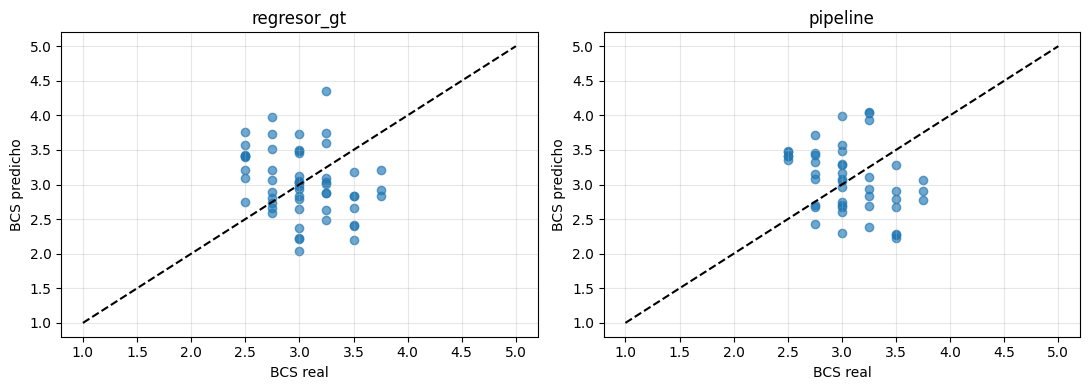

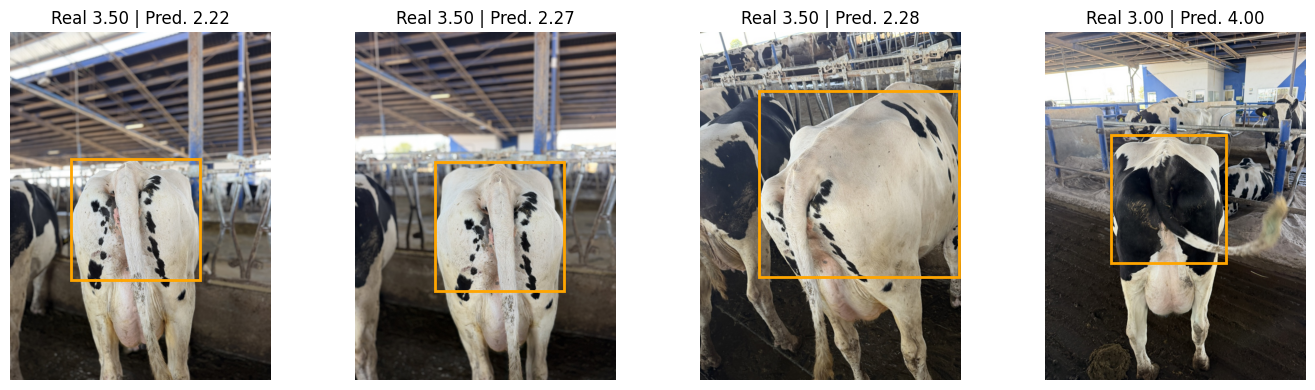

,clave,estado
4,test/15e674523dd12486e5a9c45f75c1af15da95a92ba...,sin_par_valido
14,test/359860170bbc52e4a9ea871518c79f248b91f5015...,sin_par_valido
25,test/764cef3a1be7cb41a85d0816a5dc4c45c57896399...,asociacion_ambigua
33,test/a4948d5ac3cce0e714a779b466ffabb947593078c...,asociacion_ambigua
34,test/ac828e24180f2f8a0e34decc1533b4e05e229ff23...,asociacion_ambigua
37,test/bcea561b1ca7751613a1a68850760c76f375f383a...,asociacion_ambigua
39,test/c1cf09f22d025960cbea12fb33fbd7de24138067a...,asociacion_ambigua
41,test/d21dc9ae35463a2b8bf051c7d61723bee075fcf7a...,sin_par_valido
45,test/d935ef8e365135d9c4418dcfb02c2bb4f807d7189...,asociacion_ambigua
52,test/ef42288dab9f6c4c8264c19a33db35dca39cdb44b...,sin_par_valido


In [85]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, columna in zip(ejes, ["regresor_gt", "pipeline"]):
    seleccion = predicciones[predicciones[columna].notna()]
    eje.scatter(seleccion.real, seleccion[columna], alpha=0.65)
    eje.plot([1, 5], [1, 5], "k--")
    eje.set(xlabel="BCS real", ylabel="BCS predicho", title=columna)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

predicciones["error_absoluto"] = (predicciones.pipeline - predicciones.real).abs()
peores = predicciones.dropna(subset=["pipeline"]).nlargest(4, "error_absoluto")
if len(peores):
    fig, ejes = plt.subplots(1, len(peores), figsize=(14, 4), squeeze=False)
    originales = datos.set_index("clave").ruta.to_dict()
    for eje, fila in zip(ejes[0], peores.itertuples()):
        with Image.open(originales[fila.clave]) as foto:
            eje.imshow(foto.convert("RGB"))
        x1, y1, x2, y2 = fila.caja_predicha
        eje.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="orange", linewidth=2))
        eje.set_title(f"Real {fila.real:.2f} | Pred. {fila.pipeline:.2f}")
        eje.axis("off")
    plt.tight_layout()
    plt.show()
display(predicciones.loc[predicciones.pipeline.isna(), ["clave", "estado"]].head(10))

In [86]:
resumen_estados = predicciones.groupby(["estado", "motivo_detallado"]).size().rename("observaciones").reset_index()
display(resumen_estados)
resumen_estados.to_csv(SALIDA / "abstenciones_test.csv", index=False)

,estado,motivo_detallado,observaciones
0,asociacion_ambigua,varios_pares_geometricos,6
1,ok,ok,46
2,sin_par_valido,sin_grupa_detectada,3
3,sin_par_valido,sin_vaca_detectada,1


## Tabla completa por observación

Mostramos **todas las fotos de la partición**, sin truncar la tabla. `bcs_predicho` y su error corresponden al pipeline completo. En una abstención estos valores quedan vacíos: no los sustituimos por cero ni por la predicción con caja anotada.

Las columnas `bcs_predicho_caja_anotada` y sus errores muestran separadamente el rendimiento del regresor suponiendo una localización correcta. El error con signo es **predicho − real**: positivo indica sobreestimación; negativo, subestimación. El error absoluto mide la magnitud del fallo.

El CSV conserva toda la precisión; solo redondeamos la visualización a cuatro decimales. La columna `observacion` permite reportar los casos sin publicar identificadores de animales.

In [87]:
tabla_observaciones = datos.loc[
    datos.particion == PARTICION_EVALUACION, ["clave", "bcs"]
].rename(columns={"bcs": "bcs_real"}).merge(
    predicciones[["clave", "regresor_gt", "pipeline", "estado"]],
    on="clave", how="left", validate="one_to_one"
).rename(columns={"regresor_gt": "bcs_predicho_caja_anotada", "pipeline": "bcs_predicho"})
tabla_observaciones["estado"] = tabla_observaciones.estado.fillna("bcs_real_no_evaluable")
tabla_observaciones["error"] = tabla_observaciones.bcs_predicho - tabla_observaciones.bcs_real
tabla_observaciones["error_absoluto"] = tabla_observaciones.error.abs()
tabla_observaciones["error_caja_anotada"] = (
    tabla_observaciones.bcs_predicho_caja_anotada - tabla_observaciones.bcs_real
)
tabla_observaciones["error_absoluto_caja_anotada"] = tabla_observaciones.error_caja_anotada.abs()
tabla_observaciones = tabla_observaciones.sort_values("clave").reset_index(drop=True)
tabla_observaciones.insert(0, "observacion", np.arange(1, len(tabla_observaciones) + 1))
assert len(tabla_observaciones) == int((datos.particion == PARTICION_EVALUACION).sum())
assert tabla_observaciones.clave.is_unique
ruta_tabla = SALIDA / f"tabla_observaciones_{PARTICION_EVALUACION}.csv"
tabla_observaciones.to_csv(ruta_tabla, index=False)
with pd.option_context("display.max_rows", None, "display.max_columns", None,
                       "display.max_colwidth", None, "display.float_format", "{:.4f}".format):
    display(tabla_observaciones)
print("Tabla completa guardada en:", ruta_tabla)

,observacion,clave,bcs_real,bcs_predicho_caja_anotada,bcs_predicho,estado,error,error_absoluto,error_caja_anotada,error_absoluto_caja_anotada
0,1,test/00c9c6ec228cf97c82fffbf9ad7f83d0e6774c8bff562448056e72a133ce0cc4_jpg.rf.TUHyRi6eq98bAw3Am5u9.jpg,3.7500,2.8338,2.9012,ok,-0.8488,0.8488,-0.9162,0.9162
1,2,test/06decc549e9ee72df72307a43c239bb3cbcb4e3bcfa983b18d5281b357e6f24a_jpg.rf.crkzjODfwnTb5ziB2Bb9.jpg,3.0000,2.6430,2.6090,ok,-0.3910,0.3910,-0.3570,0.3570
2,3,test/07dacce9815929655e7addd5a00f79f30002a05d27736c008f4bcdf5f8aa0f24_jpg.rf.rc7cri6Coi3PDWhlQfoe.jpg,3.5000,2.6647,2.6694,ok,-0.8306,0.8306,-0.8353,0.8353
3,4,test/0b1ef543938da4c75a71fbe5f36b2ec6d1f266b2b81193f05c70253e690967e3_jpg.rf.7Ap4J6WByepQNQKVI1GW.jpg,3.0000,3.1276,3.1604,ok,0.1604,0.1604,0.1276,0.1276
4,5,test/15e674523dd12486e5a9c45f75c1af15da95a92ba58cbd325ce6aa28d5c5ab34_jpg.rf.fpwFjt6yYHUKWmRbdmKk.jpg,3.0000,2.2326,NaN,sin_par_valido,NaN,NaN,-0.7674,0.7674
5,6,test/1797d84067ced5d5d4a77ecbeafcb4f24164ce7de9f675eb0b8e205a48fc94fb_jpg.rf.4AT2TVNBqe5gKzuY7ALc.jpg,3.2500,2.8830,4.0359,ok,0.7859,0.7859,-0.3670,0.3670
6,7,test/1c3406a16797d87688bc2034755f9603c995560b3308fd609b1664b39021aac9_jpg.rf.GctmzMjg6xZmQblSTBKC.jpg,3.5000,2.8347,2.7875,ok,-0.7125,0.7125,-0.6653,0.6653
7,8,test/1c599029af912174d9d870a1740d029a28a1f064976e682033027b8cf7607db4_jpg.rf.3al1CkiqXWWclP4YBB8t.jpg,3.2500,3.7402,3.9300,ok,0.6800,0.6800,0.4902,0.4902
8,9,test/1d80a0844e1f830f5177a5592848bfcd2bf01b3d8dd526cd8a19d451d680a968_jpg.rf.meGWrwAp6zhCG5lxUFKR.jpg,3.0000,2.3724,2.6696,ok,-0.3304,0.3304,-0.6276,0.6276
9,10,test/21c15c466bdaf35c97fce9922b047677f3508f26b6a4a7f0ed8075b158cc1f67_jpg.rf.TTrvhPMgSq5sd3G68gZv.jpg,2.7500,3.9728,3.7091,ok,0.9591,0.9591,1.2228,1.2228


Tabla completa guardada en: /kaggle/working/bcs_secuencial_v2_regresion_test/tabla_observaciones_test.csv


## 7. Generar el reporte de test

El siguiente archivo Markdown se construye con los resultados realmente calculados en esta sesión: contiene modelos elegidos, huellas, métricas, cobertura, abstenciones y una tabla anónima completa por observación. No contiene resultados simulados ni necesita instalar `tabulate`.

Las comparaciones entre v1 y v2 proceden de validación, no de test. El reporte no afirma que las diferencias sean estadísticamente significativas: las fotos de un mismo animal no son observaciones independientes.

In [88]:
def tabla_markdown(tabla):
    columnas = [str(c) for c in tabla.columns]
    lineas = ["| " + " | ".join(columnas) + " |", "| " + " | ".join(["---"] * len(columnas)) + " |"]
    for fila in tabla.itertuples(index=False, name=None):
        valores = []
        for valor in fila:
            if pd.isna(valor):
                texto = "—"
            elif isinstance(valor, (float, np.floating)):
                texto = f"{valor:.6f}"
            else:
                texto = str(valor)
            valores.append(texto.replace("|", chr(92) + "|").replace("\n", " "))
        lineas.append("| " + " | ".join(valores) + " |")
    return "\n".join(lineas)

resumen_metricas = pd.DataFrame(metricas).T.rename_axis("metodo").reset_index()
resumen_detector = pd.DataFrame(list(resultado_detector.items()), columns=["metrica", "valor"])
tabla_publicable = tabla_observaciones.drop(columns="clave")
contenido = [
    "# Test final de BCS: experimento v2",
    "Evaluación realizada en " + pd.Timestamp.now(tz="UTC").isoformat() + ".",
    "## Protocolo",
    "Modelos y umbrales fijados con validación antes de observar test. No se ha reentrenado ni elegido otro modelo con test.",
    "Fase de regresión elegida: **" + seleccion_regresor["fase"] + "**.",
    "MAE de validación del regresor elegido: " + str(seleccion_regresor["mae_validacion"][fase]) + ".",
    "Umbral de detección: " + str(CONFIANZA) + "; cobertura geométrica mínima de grupa: " + str(COBERTURA_GRUPA) + ".",
    "Particiones originales verificadas por identidad y SHA-256; datos comparados con la configuración de entrenamiento.",
    "El modelo base predice la mediana de BCS de entrenamiento. No se redondean ni limitan las predicciones para calcular errores.",
    "## Detección en test", tabla_markdown(resumen_detector),
    "## BCS y cobertura en test", tabla_markdown(resumen_metricas),
    "El MAE del pipeline excluye las abstenciones; debe interpretarse junto con cobertura. Las filas mismas_fotos comparan los métodos sobre las fotos cubiertas por el pipeline.",
    "## Estados de asociación", tabla_markdown(resumen_estados),
    "asociacion_ambigua: más de un par vaca–grupa cumple la regla. sin_par_valido: ningún par la cumple. No se fuerza una predicción ni se cuenta una abstención como error cero.",
    "Los motivos detallados y cajas con scores están en diagnostico_asociacion_test.json; las imágenes de abstenciones, en abstenciones_test/.",
    "## Hallazgos previos de validación",
    "V1: MAE con caja anotada 0.227324; v2: 0.234605. La ampliación del entrenamiento no mejoró el MAE observado. El pipeline pasó de cobertura 26/36 a 29/36, con MAE 0.292602 y 0.293458 respectivamente sobre subconjuntos diferentes.",
    "## Interpretación del test",
    "Regresor con caja anotada: MAE=" + str(metricas["regresor_gt"]["mae"]) + ". Pipeline: MAE=" + str(metricas["pipeline"]["mae"]) + ".",
    "Cobertura del pipeline=" + str(metricas["pipeline"]["cobertura"]) + "; abstenciones=" + str(metricas["pipeline"]["abstenciones"]) + ".",
    "Sobre las mismas fotos: MAE del regresor con caja anotada=" + str(metricas["regresor_gt_mismas_fotos"]["mae"]) + "; MAE base=" + str(metricas["base_mismas_fotos"]["mae"]) + ".",
    "Las diferencias entre caja anotada y predicha describen la sensibilidad a la localización; estos resultados no prueban por sí solos la causa de cada error.",
    "## Limitaciones",
    "Dataset pequeño y varias fotos por animal. Las métricas se calculan por foto, por lo que animales con más fotos pesan más. No se han calculado intervalos de confianza por animal ni pruebas de significación. Test se usa para reportar, no para ajustar umbrales o elegir v1 frente a v2.",
    "Las posibles mejoras de asociación requieren revisión y validación independientes; la regla se mantiene para este test. Los BCS son predicciones de un prototipo académico.",
    "## Huellas de la selección", "```json\n" + json.dumps(seleccion_final, indent=2) + "\n```",
    "## Todas las observaciones",
    "Error con signo = predicho − real. — indica ausencia de predicción o etiqueta evaluable. La predicción con caja anotada se reporta por separado.",
    tabla_markdown(tabla_publicable)
]
ruta_reporte = SALIDA / "hallazgos_test.md"
ruta_reporte.write_text("\n\n".join(contenido) + "\n", encoding="utf-8")
print("Reporte para documentación:", ruta_reporte)

Reporte para documentación: /kaggle/working/bcs_secuencial_v2_regresion_test/hallazgos_test.md


## 8. Descargar los resultados

El ZIP incluye el reporte, la tabla CSV completa, métricas, huellas, diagnóstico e imágenes de revisión. Excluye las copias del dataset, recortes y modelos para reducir el tamaño. Conserva también los outputs originales del entrenamiento.

El CSV y las imágenes permiten identificar observaciones del dataset: conserva estos resultados de forma privada y revisa el contenido antes de compartirlo. La tabla del Markdown usa únicamente números de observación.

In [89]:
ruta_zip = SALIDA.parent / "bcs_secuencial_v2_regresion_test_resultados.zip"
excluir = {"yolo_datos", "recortes_gt", "recortes_predichos", "detector", "regresor"}
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as archivo:
    for ruta in sorted(SALIDA.rglob("*")):
        relativa = ruta.relative_to(SALIDA)
        if ruta.is_file() and relativa.parts[0] not in excluir:
            archivo.write(ruta, str(Path(SALIDA.name) / relativa))
print("Descargar:", ruta_zip)
print("Filas en la tabla:", len(tabla_observaciones))

Descargar: /kaggle/working/bcs_secuencial_v2_regresion_test_resultados.zip
Filas en la tabla: 56
